# Driven Kitaev chain

This notebook simulates a finite, open Kitaev chain whose chemical potential is periodically driven. The state starts in the instantaneous ground state and is evolved with the time-dependent Schrödinger equation. We then measure the departure from the instantaneous ground state.

We use units with $\hbar = 1$. The many-body Hilbert-space dimension is $2^N$, so the exact calculation is intended for relatively small chains.

## 1. Numerical tools

The calculation uses sparse matrices because the fermionic operators act on a many-body Hilbert space. The time evolution is integrated with SciPy's high-order explicit solver.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.sparse import lil_matrix, csr_matrix
from scipy.sparse.linalg import eigsh
from scipy.integrate import solve_ivp

## 2. Fermionic annihilation operators

For a chain of \(N\) sites, a Fock basis state is represented by an integer whose binary digits encode site occupations. The annihilation operator \(c_j\) acts as

$$
 c_j |n_0,\ldots,n_j,\ldots,n_{N-1}\rangle
 = (-1)^{\sum_{\ell<j} n_\ell}
 n_j\,|n_0,\ldots,n_j-1,\ldots,n_{N-1}\rangle.
$$

The factor $(-1)^{\sum_{\ell<j}n_\ell}$ is the Jordan--Wigner sign required by fermionic anticommutation.

In [3]:
def annihilation_operator(N, j):
    """Fermionic annihilation operator c_j, with sites indexed from 0."""
    D = 1 << N
    c = lil_matrix((D, D), dtype=np.complex128)

    for state in range(D):
        if (state >> j) & 1:
            target = state ^ (1 << j)

            # Jordan-Wigner sign from occupied sites to the left.
            lower_bits = state & ((1 << j) - 1)
            sign = (-1) ** lower_bits.bit_count()

            c[target, state] = sign

    return c.tocsr()

## 3. Kitaev-chain Hamiltonian

The open-chain Hamiltonian is

$$
H_0 = -\mu\sum_{j=0}^{N-1}\left(c_j^\dagger c_j - \frac12\right)
- t\sum_{j=0}^{N-2}\left(c_j^\dagger c_{j+1}+c_{j+1}^\dagger c_j\right)
+ \Delta\sum_{j=0}^{N-2}\left(c_jc_{j+1}+c_{j+1}^\dagger c_j^\dagger\right).
$$

The total particle-number operator is

$$
\hat{N}=\sum_{j=0}^{N-1}c_j^\dagger c_j.
$$

The default choice \(\Delta=t\) is the commonly used symmetric point of the Kitaev model.

In [4]:
def build_kitaev_chain(N, mu, t_hop, delta=None):
    """Build the static Kitaev Hamiltonian and total number operator."""
    if delta is None:
        delta = t_hop

    if N < 2:
        raise ValueError("N must be at least 2.")

    D = 1 << N
    identity = csr_matrix(np.eye(D, dtype=np.complex128))

    c = [annihilation_operator(N, j) for j in range(N)]
    cd = [op.getH() for op in c]

    number_op = csr_matrix((D, D), dtype=np.complex128)
    H = csr_matrix((D, D), dtype=np.complex128)

    for j in range(N):
        nj = cd[j] @ c[j]
        number_op += nj
        H += -mu * (nj - 0.5 * identity)

    for j in range(N - 1):
        H += -t_hop * (cd[j] @ c[j + 1] + cd[j + 1] @ c[j])
        H += delta * (c[j] @ c[j + 1] + cd[j + 1] @ cd[j])

    return H.tocsr(), number_op.tocsr()

## 4. Periodic drive and parity sector

The chemical potential is modulated as

$$
\mu(t)=\mu+A\cos(\omega t).
$$

Therefore, since the chemical-potential contribution is $-\mu\hat N$, the driven Hamiltonian can be written as

$$
H(t)=H_0-A\cos(\omega t)\,\hat N.
$$

The Hamiltonian preserves fermion parity, $P=(-1)^{\hat N}$, so we restrict the calculation to either the even or odd sector. This reduces the matrix dimension from $2^N$ to $2^{N-1}$.

In [5]:
def simulate_kitaev(
    mu,
    t_hop,
    N,
    A,
    omega,
    T,
    num_times=401,
    parity="even",
    delta=None,
    rtol=1e-9,
    atol=1e-11,
):
    """Simulate a periodically driven Kitaev chain."""
    if A < 0:
        raise ValueError("A must be nonnegative.")
    if omega < 0:
        raise ValueError("omega must be nonnegative.")
    if T <= 0 or num_times < 2:
        raise ValueError("T must be positive and num_times >= 2.")

    if delta is None:
        delta = t_hop

    H0, number_op = build_kitaev_chain(N, mu, t_hop, delta)

    D = 1 << N
    if parity == "even":
        basis = np.array([s for s in range(D) if s.bit_count() % 2 == 0])
    elif parity == "odd":
        basis = np.array([s for s in range(D) if s.bit_count() % 2 == 1])
    else:
        raise ValueError("parity must be 'even' or 'odd'.")

    H0 = H0[basis, :][:, basis].tocsr()
    number_op = number_op[basis, :][:, basis].tocsr()

    def H_of_time(time):
        return H0 - A * np.cos(omega * time) * number_op

    # Initial instantaneous ground state at t = 0.
    _, initial_vectors = eigsh(H_of_time(0.0), k=1, which="SA")
    psi0 = initial_vectors[:, 0]
    psi0 /= np.linalg.norm(psi0)

    # Time-dependent Schrodinger equation with hbar = 1.
    def rhs(time, psi):
        return -1j * (H_of_time(time) @ psi)

    times = np.linspace(0.0, T, num_times)
    solution = solve_ivp(
        rhs,
        (0.0, T),
        psi0,
        t_eval=times,
        rtol=rtol,
        atol=atol,
        method="DOP853",
    )

    if not solution.success:
        raise RuntimeError(solution.message)

    leakage = np.empty(len(times))
    for k, time in enumerate(times):
        psi = solution.y[:, k]
        psi /= np.linalg.norm(psi)

        _, vectors = eigsh(H_of_time(time), k=1, which="SA")
        ground = vectors[:, 0]

        fidelity = abs(np.vdot(ground, psi)) ** 2
        leakage[k] = np.clip(1.0 - fidelity, 0.0, 1.0)

    return times, leakage

## 5. Simulation and Leakage

The state is initialized as the lowest-energy state of $H(0)$ in the even-parity sector.
The leakage at time $t$ is defined as
$$
\mathcal{L}(t) = 1 - |\langle g(t) | \psi(t) \rangle|^2,
$$
where $|\psi(t)\rangle$ is the evolved state and $|g(t)\rangle$ is the instantaneous ground state.
We plot $\mathcal{L}(t)$ as a function of $t$.

In [16]:
def simulate_and_plot(
    mu,
    t_hop,
    N,
    A,
    omega,
    T,
    num_times=401,
    parity="even",
    delta=None,
    rtol=1e-9,
    atol=1e-11,
    figsize=(8,5),
    xlabel="Time",
    ylabel="Instantaneous ground-state leakage",
    title=None,
):
    times, leakage = simulate_kitaev(
        mu=mu,
        t_hop=t_hop,
        N=N,
        A=A,
        omega=omega,
        T=T,
        num_times=num_times,
        parity=parity,
    )

    if title is None:
        title = f"Kitaev chain, mu={mu}, t={t_hop}, N={N}, A={A}, w={omega}, T={T}"
    plt.figure(figsize=figsize)
    plt.plot(times, leakage)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.tight_layout()
    plt.show()

    return times, leakage

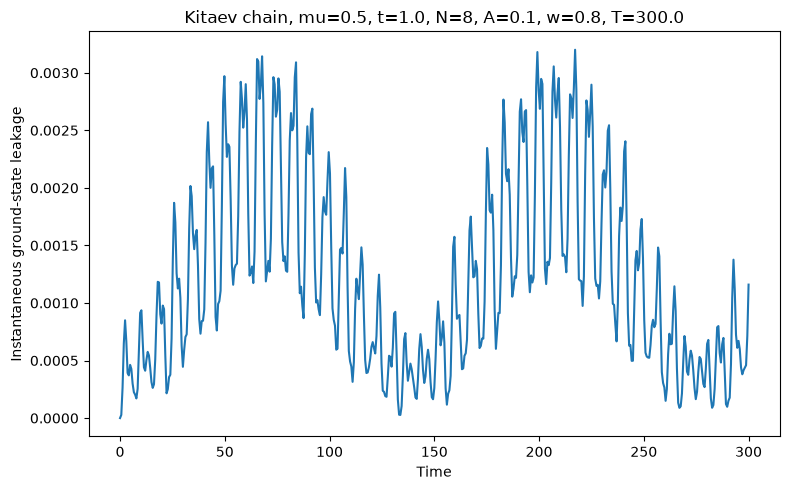

In [22]:
times1, leakage1 = simulate_and_plot(
    mu=0.5,
    t_hop=1.0,
    N=8,
    A=0.1,
    omega=0.8,
    T=300.0,
    num_times=501,
    parity="even",
)

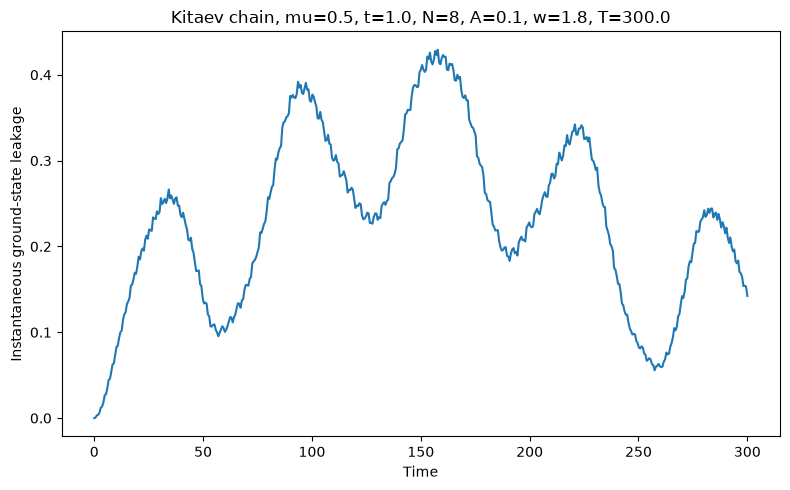

In [23]:
times2, leakage2 = simulate_and_plot(
    mu=0.5,
    t_hop=1.0,
    N=8,
    A=0.1,
    omega=1.8,
    T=300.0,
    num_times=501,
    parity="even",
)

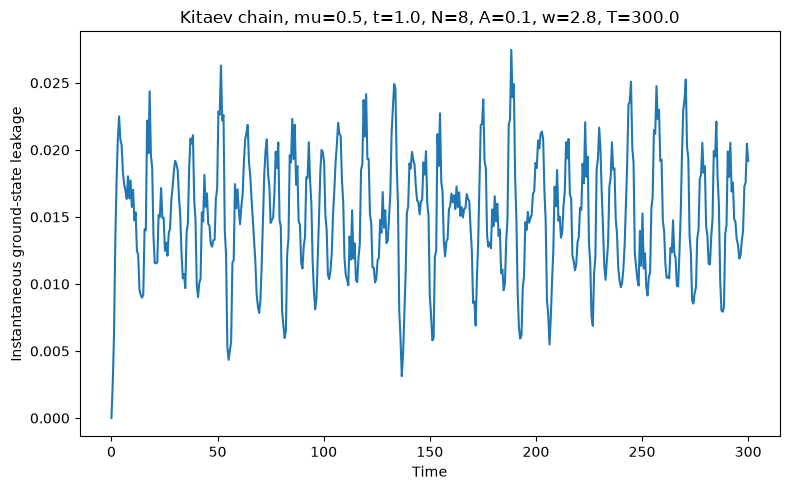

In [24]:
times3, leakage3 = simulate_and_plot(
    mu=0.5,
    t_hop=1.0,
    N=8,
    A=0.1,
    omega=2.8,
    T=300.0,
    num_times=501,
    parity="even",
)

In [26]:
def extract_frequency_spectrum(timestamps, signal_values):
    """
    Extracts the frequency-amplitude relation from a timed signal.
    
    Parameters:
        timestamps (array-like): Monotonically increasing time values (seconds)
        signal_values (array-like): The signal magnitude at each timestamp
        
    Returns:
        frequencies (array): Frequency bins up to the Nyquist limit (Hz)
        amplitudes (array): True physical amplitude at each frequency
    """
    # Ensure inputs are numpy arrays
    t = np.asarray(timestamps)
    x = np.asarray(signal_values)
    N = len(x)
    
    # 1. Calculate the uniform sample spacing (dt)
    # Uses the average diff to smooth out tiny floating-point jitter
    dt = np.mean(np.diff(t)) 
    
    # 2. Compute the Real Fast Fourier Transform (RFFT)
    # rfft skips the redundant negative frequencies, saving memory and compute
    fft_complex = np.fft.rfft(x)
    
    # 3. Generate the true physical frequency axes
    frequencies = np.fft.rfftfreq(N, d=dt)
    
    # 4. Extract and normalize the magnitude to get physical amplitude
    # - Divide by N to scale the magnitude correctly.
    # - Multiply by 2 because rfft discards half the energy (negative frequencies).
    amplitudes = (np.abs(fft_complex) / N) * 2
    
    # Correction for DC component (0 Hz) and Nyquist frequency (if N is even)
    # These frequencies do not have a negative twin, so they shouldn't be doubled
    amplitudes[0] /= 2
    if N % 2 == 0:
        amplitudes[-1] /= 2
        
    return frequencies, amplitudes

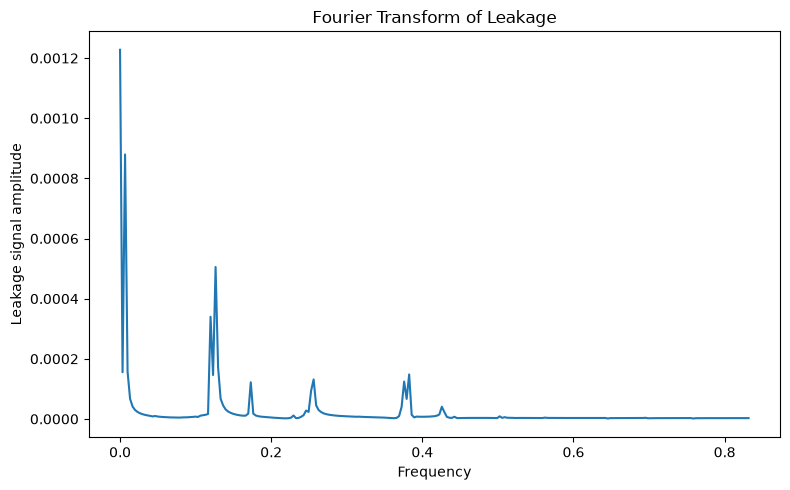

In [27]:
freqs, amps = extract_frequency_spectrum(times1, leakage1)
plt.figure(figsize=(8, 5))
plt.plot(freqs, amps)
plt.xlabel("Frequency")
plt.ylabel("Leakage signal amplitude")
plt.title("Fourier Transform of Leakage")
plt.tight_layout()
plt.show()

## Interpretation

The oscillatory curve measures the competition between the periodic drive and the system's intrinsic many-body dynamics. The calculation is exact for the finite chain and chosen parity sector, but its cost grows exponentially with $N$ because the Hilbert-space dimension is $2^N$ (or $2^{N-1}$ after parity reduction).